# DiscoveryWorld multi-agent test

The run cell starts two agents in the same Archaeology Dating world. Each agent chooses one action per round, then the shared world advances once. Each agent sees its own observation and action history. The continuation cells keep the same world and histories.

Set `spawnSeed` in the run cell to assign agents to distinct scenario landmarks. Change only this seed to try a different starting layout on the same map, or pass `None` to use the scenario's default positions. Saved output without spawn lines is from the earlier default-spawn run.

DiscoveryWorld saves offscreen UI frames for each agent in `api.FRAME_DIR`. The notebook also saves `shared_world_frame_*.png` there at spawn and after each round. These frames show the entire map, with agent IDs marked on their tiles. Run the last cell to display the latest shared frame.

In [5]:
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv

load_dotenv()

model = ChatOpenAI(
        model="gpt-6-luna",
        reasoning_effort="medium",
        max_retries=3,
        timeout=60,
    )

In [6]:
from pydantic import BaseModel, Field

class ActionResponse(BaseModel):
    """An action and its arguments for the DiscoveryWorld agent."""

    action: str = Field(description="Name of the action to perform")
    arg1: int | str | None = Field(description="First argument, or null if unused")
    arg2: int | str | None = Field(description="Second argument, or null if unused")

class DialogResponse(BaseModel):
    """An option selected from the current dialog."""
    chosen_dialog_option_int: int = Field(description="Number of the dialog option to select")


def submitLLMPrompt(prompt: str, in_dialog: bool = False) -> dict:
    schema = DialogResponse if in_dialog else ActionResponse
    response = model.with_structured_output(schema).invoke(prompt)
    return response.model_dump(mode="json")


In [7]:
import json
import time
from random import Random
from collections import defaultdict
from pathlib import Path

import pygame
from discoveryworld.DiscoveryWorldAPI import DiscoveryWorldAPI
from discoveryworld.Layer import Layer


def navigation_loop_detected(actions_taken, window=6):
    """Detect repeated positions during travel with unchanged inventory."""
    recent = actions_taken[-window:]
    navigation = {"MOVE_DIRECTION", "ROTATE_DIRECTION", "TELEPORT_TO_OBJECT", "TELEPORT_TO_LOCATION"}
    if len(recent) < window or any(r["action"].get("action") not in navigation for r in recent):
        return False
    inventories = [json.dumps(r.get("inventory", []), sort_keys=True) for r in recent]
    positions = [(r["location"]["x"], r["location"]["y"]) for r in recent]
    return len(set(inventories)) == 1 and len(set(positions)) <= window // 2


def agent_step(api, observation, actions_taken, agentIdx=0):
    """Choose one action using the current state and previous outcomes."""
    prompt = (
        f"You are DiscoveryWorld agent {agentIdx}. Complete the task described in your observation.\n"
        "Choose one action at a time and check its outcome before continuing.\n"
        "Teleporting moves only you, not the target object. Pick up movable objects "
        "before taking them elsewhere. Both arguments of USE must be accessible "
        "simultaneously (in inventoryObjects or accessibleEnvironmentObjects).\n"
        "After reaching an object, perform the needed interaction before leaving. "
        "Use directions_you_can_move for movement; rotate to face nearby objects.\n"
        "Review your history. Avoid repeating travel without task progress. "
        "If travel repeats, identify the missing interaction or prerequisite.\n"
        "For chemical experiments, keep track of chemicals tried and outcomes; "
        "follow the task's instructions for cleaning the jar between trials.\n"
        "Use only supplied UUIDs and valid actions. Use null for unused arguments.\n"
    )
    prompt += "Current observation:\n" + json.dumps(observation["ui"], indent=2)
    prompt += "\nAvailable actions:\n" + json.dumps(api.listKnownActions(limited=False), indent=2)
    prompt += "\nTeleport locations:\n" + json.dumps(api.listTeleportLocationsDict(), indent=2)
    prompt += "\nAction history (including outcomes):\n" + json.dumps(actions_taken, indent=2)
    if navigation_loop_detected(actions_taken):
        prompt += (
            "\nLOOP DETECTED: Recent navigation revisits the same positions with "
            "unchanged inventory. Identify the missing prerequisite. Prefer an "
            "accessible interaction that advances the task; collect needed movable "
            "objects before leaving. Do not repeat the same travel cycle."
        )
    in_dialog = api.isAgentInDialog(agentIdx=agentIdx)
    if in_dialog:
        prompt += (
            "\nYou are in dialog. Select a listed option from dialog_box and return "
            "chosen_dialog_option_int instead of an ordinary action."
        )
    return submitLLMPrompt(prompt, in_dialog=in_dialog)


def randomize_start_positions(api, spawnSeed):
    world = api.world
    agents = world.getUserAgents()
    occupied = {agent.getWorldLocation() for agent in agents + world.getNPCAgents()}
    landmarks = {}
    for name, location in sorted(world.getTeleportLocations().items()):
        position = (location["gridX"], location["gridY"])
        if position not in occupied and world.isPassable(*position)[0]:
            landmarks.setdefault(position, name)
    if len(landmarks) < len(agents):
        raise ValueError(f"Need {len(agents)} unoccupied landmarks, found {len(landmarks)}.")

    positions = Random(spawnSeed).sample(list(landmarks), len(agents))
    for agent_idx, (agent, (x, y)) in enumerate(zip(agents, positions)):
        world.removeObject(agent)
        world.addObject(x, y, Layer.AGENT, agent)
        print(f"Agent {agent_idx} spawn: {landmarks[(x, y)]} at ({x}, {y})")


def save_shared_frame(api):
    world = api.world
    tile_size = 32
    surface = pygame.Surface((world.sizeX * tile_size, world.sizeY * tile_size))
    world.renderViewport(surface, 0, 0, world.sizeX, world.sizeY, 0, 0)

    ids_by_tile = defaultdict(list)
    for agent_idx, agent in enumerate(world.getUserAgents()):
        ids_by_tile[agent.getWorldLocation()].append(str(agent_idx))
    font = pygame.font.Font(None, 20)
    for (x, y), agent_ids in ids_by_tile.items():
        tile = pygame.Rect(x * tile_size, y * tile_size, tile_size, tile_size)
        pygame.draw.rect(surface, (255, 223, 94), tile, width=2)
        label = font.render('/'.join(agent_ids), True, (255, 223, 94), (25, 25, 25))
        label_rect = label.get_rect(midbottom=tile.midtop if y else tile.midbottom)
        surface.blit(label, label_rect.clamp(surface.get_rect()))

    path = Path(api.FRAME_DIR) / f"shared_world_frame_{world.getStepCounter():04d}.png"
    pygame.image.save(surface, str(path))
    return path


def exampleLoop(scenarioName, difficultyStr, randomSeed, maxSteps=20, numUserAgents=2, spawnSeed=None):
    """Start a shared world and run the requested number of agents."""
    api = DiscoveryWorldAPI(threadID=time.time_ns())
    if not api.loadScenario(scenarioName=scenarioName, difficultyStr=difficultyStr,
                            randomSeed=randomSeed, numUserAgents=numUserAgents):
        raise RuntimeError(f"Could not load {scenarioName} ({difficultyStr})")
    if api.numUserAgents != numUserAgents:
        raise ValueError(
            f"{scenarioName} ({difficultyStr}) spawned {api.numUserAgents} user agents "
            f"but this test requested {numUserAgents}."
        )

    if spawnSeed is not None:
        randomize_start_positions(api, spawnSeed)

    actions_taken_by_agent = {agent_idx: [] for agent_idx in range(api.numUserAgents)}
    save_shared_frame(api)
    return continueLoop(api, actions_taken_by_agent, maxSteps=maxSteps)


def continueLoop(api, actions_taken_by_agent, maxSteps=20):
    """Advance the existing world by up to maxSteps rounds and extend each history."""
    start_step = max(
        (history[-1]["step"] for history in actions_taken_by_agent.values() if history),
        default=-1,
    ) + 1
    for step in range(start_step, start_step + maxSteps):
        if api.areTasksComplete():
            break

        for agent_idx in range(api.numUserAgents):
            history = actions_taken_by_agent[agent_idx]
            observation = api.getAgentObservation(agentIdx=agent_idx)
            if observation.get("errors"):
                raise RuntimeError(f"Observation errors for agent {agent_idx}: {observation['errors']}")
            if navigation_loop_detected(history):
                print(f"Agent {agent_idx}: repeated travel detected.")
            action = agent_step(api, observation, history, agentIdx=agent_idx)
            result = api.performAgentAction(agentIdx=agent_idx, actionJSON=action.copy())
            observation = api.getAgentObservation(agentIdx=agent_idx)
            if observation.get("errors"):
                raise RuntimeError(f"Observation errors for agent {agent_idx}: {observation['errors']}")
            ui = observation["ui"]
            message = ui.get("lastActionMessage", "")
            history.append({
                "step": step,
                "action": action,
                "result": result,
                "message": message,
                "location": ui["agentLocation"],
                "inventory": ui["inventoryObjects"],
            })
            print(f"Agent {agent_idx}, round {step}: {json.dumps(action)}")
            print(f"  Success: {result.get('success')} | {message}")

        tick_result = api.tick()
        if not tick_result.get("success"):
            raise RuntimeError(tick_result)
        save_shared_frame(api)

    print("Scorecard:", json.dumps(api.getTaskScorecard(), indent=2))
    return api, actions_taken_by_agent


In [8]:
# Run after the model, schema, and function definition cells.
api, actions_taken_by_agent = exampleLoop(
    scenarioName="Reactor Lab",
    difficultyStr="Easy",
    randomSeed=0,
    maxSteps=5,
    numUserAgents=2,
    spawnSeed=42,
)


Loading sprites from index file: C:\dev\AI\Dundalk\advanced_agentic\project_code\environment\discoveryworld\discoveryworld\assets\spriteIndex.json
	Loaded 36 sprites from pixymoon/CuteRPG_Interior/32x32/CuteRPG_Interior_custom.png.
	Loaded 22 sprites from pixymoon/CuteRPG_Houses/32x32/CuteRPG_Houses_A-modified1.png.
	Loaded 30 sprites from pixymoon/CuteRPG_Desert/32x32/CuteRPG_Desert_Outside_modified.png.
	Loaded 1 sprites from pixymoon/CuteRPG_Desert/32x32/CuteRPG_Desert_Inside.png.
	Loaded 9 sprites from pixymoon/CuteRPG_Village/32x32/CuteRPG_Village_House.png.
	Loaded 9 sprites from pixymoon/CuteRPG_Houses/32x32/CuteRPG_Houses_C.png.
	Loaded 25 sprites from placeholder/instruments2.png.
	Loaded 46 sprites from pixymoon/CuteRPG_Forest/32x32/CuteRPG_Forest_modified2.png.
	Loaded 22 sprites from pixymoon/CuteRPG_Village/32x32/CuteRPG_Village.png.
	Loaded 14 sprites from pixymoon/CuteRPG_Caves/32x32/CuteRPG_Caves.png.
	Loaded 24 sprites from pixymoon/CuteRPG_Castle_New/32x32/CuteRPG_Cas

ValueError: Need 2 unoccupied landmarks, found 0.

## Continue the existing run

Run a continuation cell to take up to 20 more rounds in the current world. Each round can make one model call per agent. After a kernel restart, run the setup and fresh-run cells again.

In [ ]:
api, actions_taken_by_agent = continueLoop(api, actions_taken_by_agent, maxSteps=20)

Agent 0, round 5: {"action": "PICKUP", "arg1": 47477, "arg2": null}
  Success: True | I picked up the shovel.
Agent 1, round 5: {"action": "TELEPORT_TO_LOCATION", "arg1": "dig site 1", "arg2": null}
  Success: True | I teleported to dig site 1 at 9, 11.
Saving world history...
Number of items in world history:7
Size of most recent item: 16688 bytes 16.296875 KB
World history includes 1087 objects.
World history saved in 0.016654014587402344 seconds.
Agent 0, round 6: {"action": "TELEPORT_TO_LOCATION", "arg1": "dig site 1", "arg2": null}
  Success: True | I teleported to dig site 1 at 9, 11.
Agent 1, round 6: {"action": "ROTATE_DIRECTION", "arg1": "east", "arg2": null}
  Success: True | I rotated to face east.
Saving world history...
Number of items in world history:8
Size of most recent item: 16601 bytes 16.2119140625 KB
World history includes 1087 objects.
World history saved in 0.018938779830932617 seconds.
Agent 0, round 7: {"action": "ROTATE_DIRECTION", "arg1": "east", "arg2": null

In [ ]:
api, actions_taken_by_agent = continueLoop(api, actions_taken_by_agent, maxSteps=20)

Agent 0, round 25: {"action": "MOVE_DIRECTION", "arg1": "east", "arg2": null}
  Success: True | I moved to (12, 19).
Agent 1, round 25: {"action": "TELEPORT_TO_OBJECT", "arg1": 41671, "arg2": null}
  Success: True | I teleported to the object with UUID 41671 (ancient artifact) at (13, 19).
Saving world history...
Number of items in world history:27
Size of most recent item: 17024 bytes 16.625 KB
World history includes 1087 objects.
World history saved in 0.020016908645629883 seconds.
Agent 0, round 26: {"action": "USE", "arg1": 47477, "arg2": 60834}
  Success: True | You dig a hole in the soil, creating a hole and dirt.
Agent 1, round 26: {"action": "PICKUP", "arg1": 41671, "arg2": null}
  Success: True | I picked up the ancient artifact.
Saving world history...
Number of items in world history:28
Size of most recent item: 16768 bytes 16.375 KB
World history includes 1087 objects.
World history saved in 0.01709747314453125 seconds.
Agent 0, round 27: {"action": "PICKUP", "arg1": 20359,

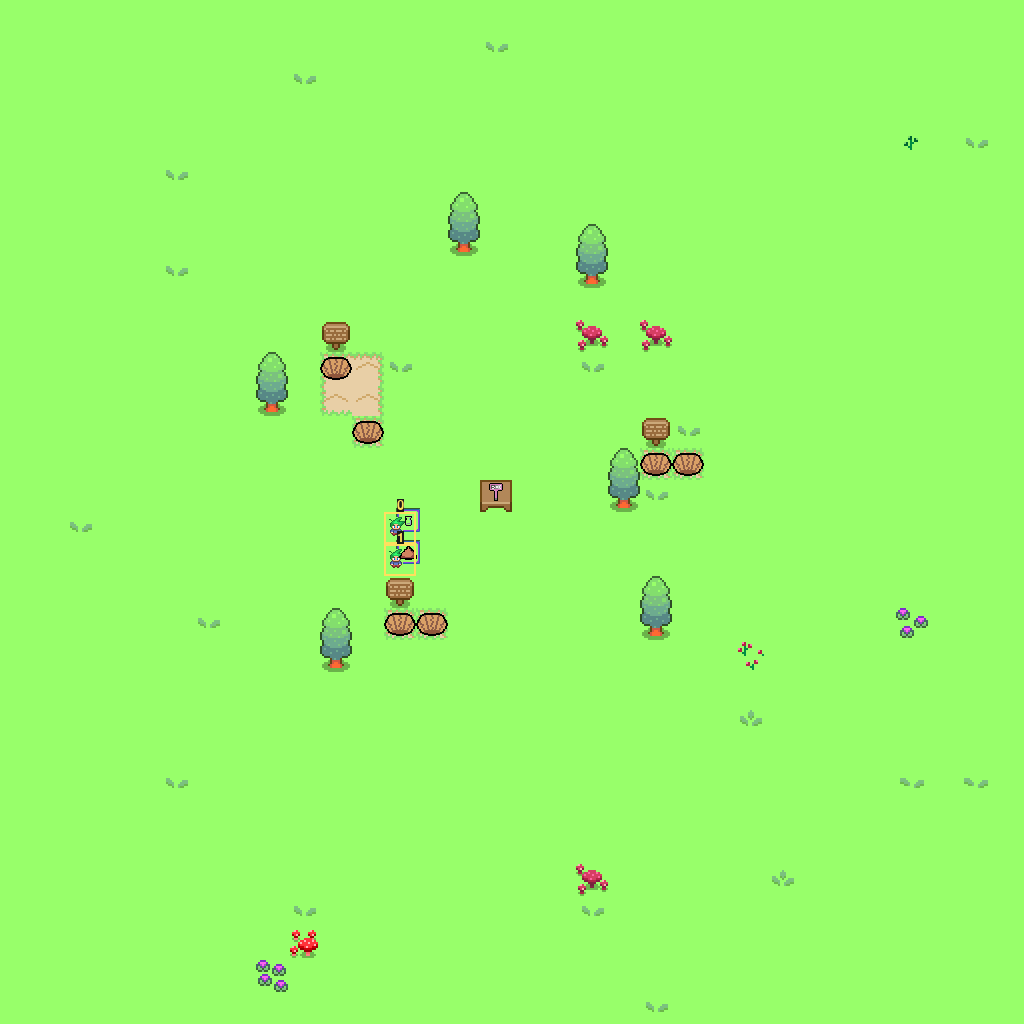

In [ ]:
from IPython.display import Image, display

display(Image(filename=str(save_shared_frame(api)), width=800))

In [ ]:
api, actions_taken_by_agent = continueLoop(api, actions_taken_by_agent, maxSteps=20)

Scorecard: [
  {
    "taskName": "ArchaeologyDigTaskNormal",
    "taskDescription": "You are on an archaeological dig on Planet X.  3 ancient sites have been found. Your task is to excavate the sites, and date any artifacts with the radiocarbon meter.  Then, once completed, place the red flag beside the sign of the dig site with the oldest artifact. ",
    "score": 8,
    "maxScore": 10,
    "scoreNormalized": 0.8,
    "completed": true,
    "completedSuccessfully": false,
    "scoreCard": [
      {
        "name": "Take radiocarbon meter",
        "description": "The radiocarbon meter has been in an agent's inventory",
        "maxScore": 1,
        "score": 0,
        "completed": false,
        "associatedUUIDs": [],
        "associatedNotes": ""
      },
      {
        "name": "Take shovel",
        "description": "The shovel has been in an agent's inventory",
        "maxScore": 1,
        "score": 1,
        "completed": true,
        "associatedUUIDs": [
          47477
       

In [ ]:
# logFileSuffix = f"{api.scenarioName}.{api.difficultyStr}.seed{api.randomSeed}.agents{api.numUserAgents}"
# filenameOut = "mmultiagent." + logFileSuffix + ".mp4"
# api.createAgentVideo(agentIdx=0, filenameOut=filenameOut)